Credit score (gradient boosting)

In [160]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import kagglehub

from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_curve, precision_score, recall_score, auc, f1_score, classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize

ДАТАСЕТ

In [162]:
path = kagglehub.dataset_download("parisrohan/credit-score-classification")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\bvo5\.cache\kagglehub\datasets\parisrohan\credit-score-classification\versions\1


In [163]:
train = pd.read_csv(f'{path}\\train.csv', low_memory=False)
train_copy = train

In [164]:
train.head(2)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.82262,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.94496,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good


In [165]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Name                      90015 non-null   object 
 4   Age                       100000 non-null  object 
 5   SSN                       100000 non-null  object 
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  object 
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  object 
 13  Type_of_Loan              88592 non-null   ob

Датасет содержит 100000 строк-клиентов и 27 признаков. Некоторые из которых - категориальные, а именно "Month", "Occupation", "Type_of_Loan", "Credit_Mix", "Payment_Behaviour", "Payment_of_Min_Amount". 
Признаки 'ID', 'Customer_ID', 'Name', 'SSN' явл. лишь метаинформацией, которая не участвует в корреляции с целевой переменной, их можно отбросить.
Некоторые столбцы содерждат пропуски, что для бустинга не критично.

In [167]:
train.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,84998.000000,100000.000000,100000.00000,100000.000000,100000.000000,98035.000000,100000.000000,100000.000000
mean,4194.170850,17.091280,22.47443,72.466040,21.068780,27.754251,32.285173,1403.118217
std,3183.686167,117.404834,129.05741,466.422621,14.860104,193.177339,5.116875,8306.041270
min,303.645417,-1.000000,0.00000,1.000000,-5.000000,0.000000,20.000000,0.000000
25%,1625.568229,3.000000,4.00000,8.000000,10.000000,3.000000,28.052567,30.306660
50%,3093.745000,6.000000,5.00000,13.000000,18.000000,6.000000,32.305784,69.249473
75%,5957.448333,7.000000,7.00000,20.000000,28.000000,9.000000,36.496663,161.224249
max,15204.633333,1798.000000,1499.00000,5797.000000,67.000000,2597.000000,50.000000,82331.000000


In [168]:
#Функция для обработки признака Credit_History_Age, переводит строку в интепретируеморе число
def Credit_History_Age(s=str):
    try:
        y, m = map(int, s[:s.rfind(' ')].split(" Years and "))
        return y + m/12
    except:
        return s

In [169]:
#Дропаем признаки, не связанные с целевой переменной 
train = train.drop(columns=['ID', 'Customer_ID', 'Name', 'SSN'])
#Меняем Credit_History_Age
train["Credit_History_Age"] = train["Credit_History_Age"].apply(lambda s: Credit_History_Age(s))

In [170]:
train.head(2)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,January,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,_,809.98,26.82262,22.083333,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,February,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,Good,809.98,31.94496,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good


In [171]:
#Выделяем категориальные признаки
cat_features = ["Month", "Occupation", "Type_of_Loan", "Credit_Mix", "Payment_Behaviour", "Payment_of_Min_Amount"]

In [172]:
# Обработка артефактных значений
def drop_artifact_rows(df, columns):
    mask = pd.Series(False, index=df.index)
    for col in columns:
        converted = pd.to_numeric(df[col], errors='coerce')
        artifacts = df[col].notna() & converted.isna()
        mask = mask | artifacts
        print(f"В колонке '{col}' найдено артефактов: {artifacts.sum()}")

    df_cleaned = df[~mask].copy()
    for col in columns:
        df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='ignore')
    return df_cleaned

В некоторых столбцах, содержащих только числовые значения (float), встречаются артефакты по типу '28_' (string). Нижняя функция чистит датасет от этого, а именно удаляет из него целую строки, если в одном из признаков есть такой артефакт.

In [174]:
for col in train.drop(columns = cat_features).columns:
    try:
        train[col].astype(float)
    except ValueError:
        print(f"Ошибка в столбце: {col}")

Ошибка в столбце: Age
Ошибка в столбце: Annual_Income
Ошибка в столбце: Num_of_Loan
Ошибка в столбце: Num_of_Delayed_Payment
Ошибка в столбце: Changed_Credit_Limit
Ошибка в столбце: Outstanding_Debt
Ошибка в столбце: Amount_invested_monthly
Ошибка в столбце: Monthly_Balance
Ошибка в столбце: Credit_Score


Получены столбцы с артефактами

In [176]:
train = drop_artifact_rows(train, ["Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Outstanding_Debt", "Amount_invested_monthly", "Monthly_Balance"])

В колонке 'Age' найдено артефактов: 4939
В колонке 'Annual_Income' найдено артефактов: 6980
В колонке 'Num_of_Loan' найдено артефактов: 4785
В колонке 'Num_of_Delayed_Payment' найдено артефактов: 2744
В колонке 'Changed_Credit_Limit' найдено артефактов: 2091
В колонке 'Outstanding_Debt' найдено артефактов: 1009
В колонке 'Amount_invested_monthly' найдено артефактов: 4305
В колонке 'Monthly_Balance' найдено артефактов: 9


C:\Users\bvo5\AppData\Local\Temp\ipykernel_14276\3337511268.py:12: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='ignore')


In [177]:
# Превращаем все категориальные признаки в string. NaN станут строками 'nan' (нужно для catboost)
for col in cat_features:
    train[col] = train[col].astype(str)

In [178]:
train.head(2)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,January,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,_,809.98,26.82262,22.083333,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good
1,February,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,Good,809.98,31.94496,NaN,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good


Разбиваем выборку на обучающую и тестовую

In [180]:
y, X = train['Credit_Score'], train.drop('Credit_Score', axis=1) 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

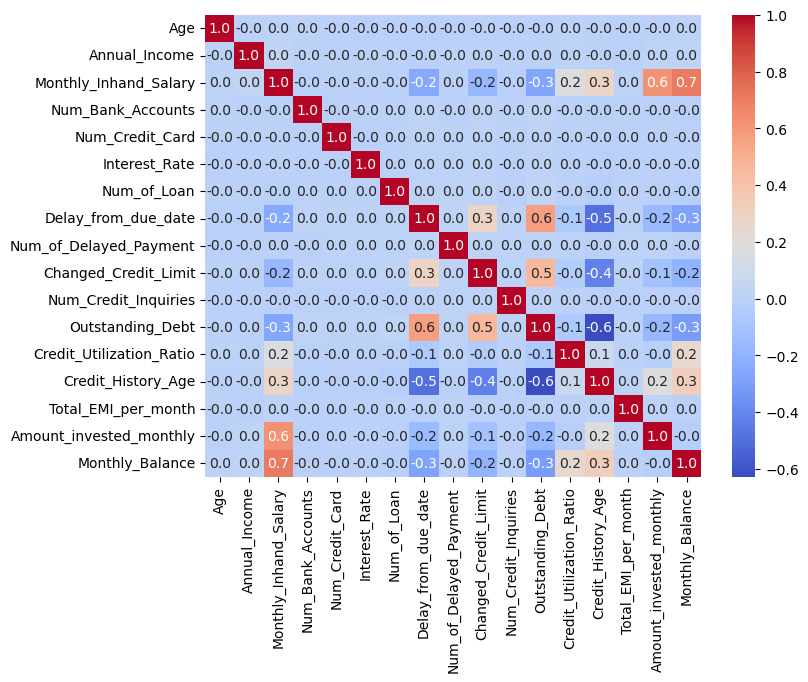

In [181]:
# Смотрим на попарную корреляцию признаков
corr = X_train.drop(columns = cat_features).corr()
# Plot the heatmap
plt.figure(figsize=(8, 6)) # Optional: Adjust figure size
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt=".1f")
plt.show()

По матрице корелляции видно некоторые признаки, которые обладают небольшой линейной связью. Максимальное по модулю значение коэф. корелляции это 0.7 между признаками Monthly_Balance и Monthly_Inhand_Salary. Но его не достаточно, для того, чтобы удалить один из признаков, т.к. потеряется часть полезной информации.

Посмотрим на распределение каждого признака

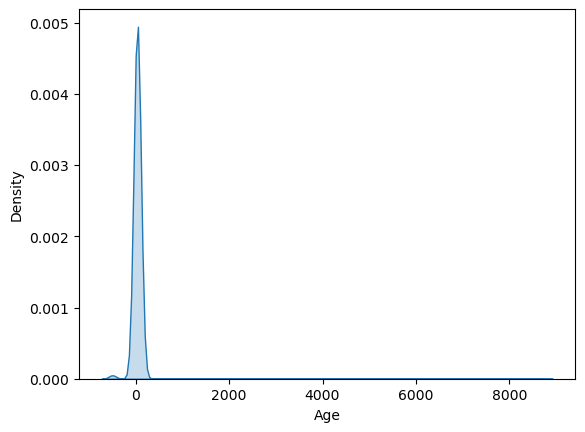

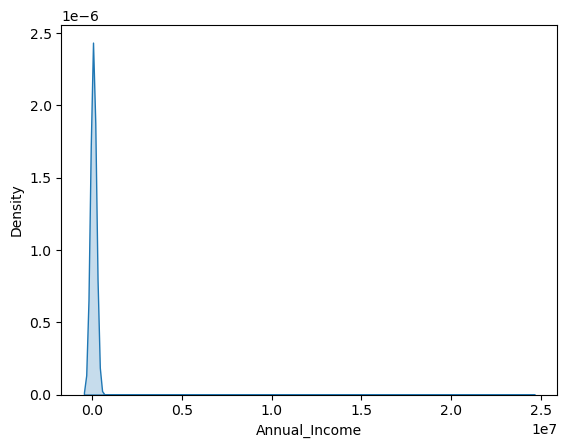

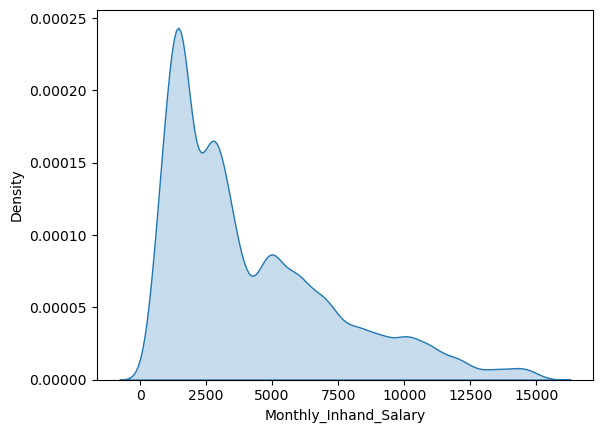

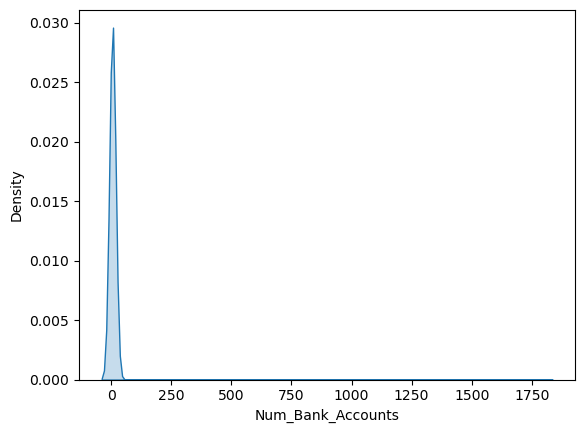

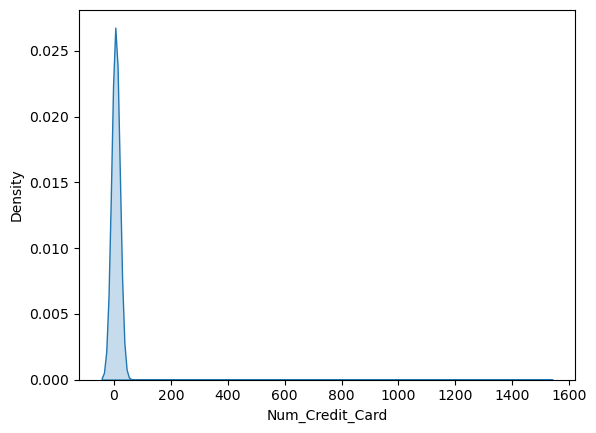

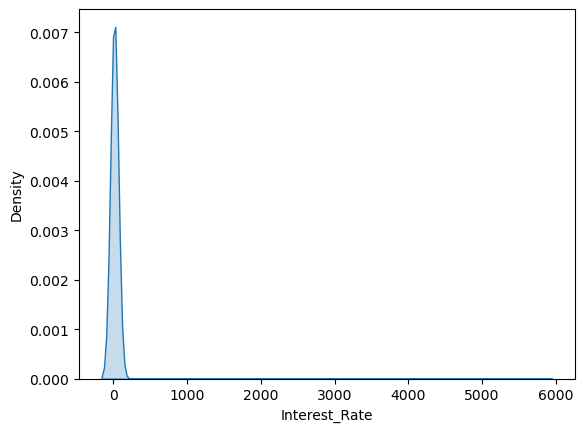

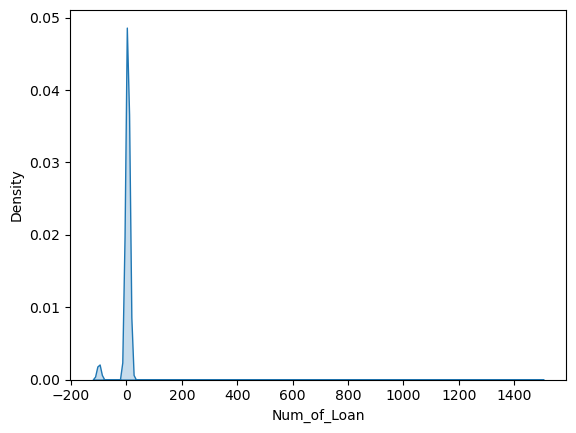

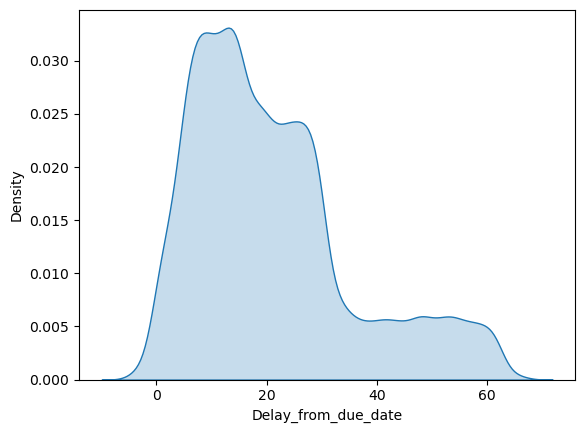

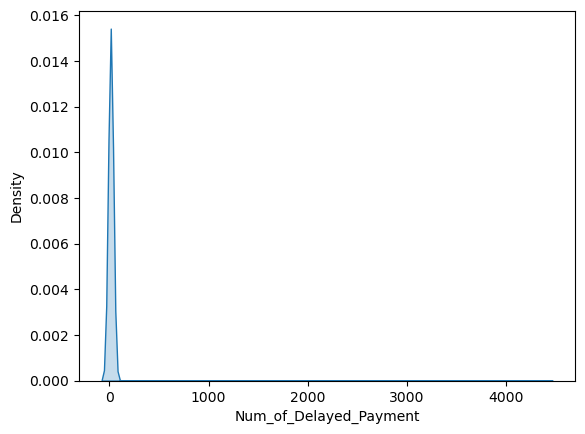

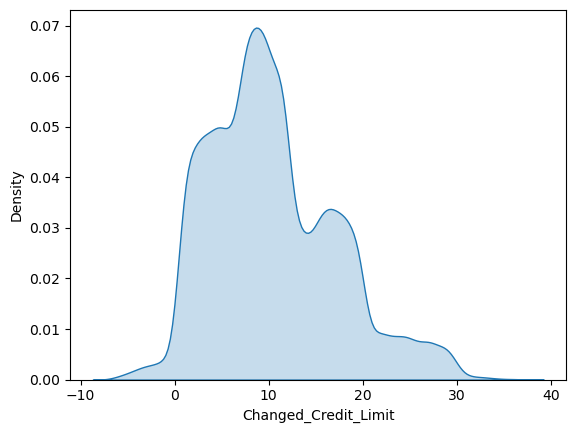

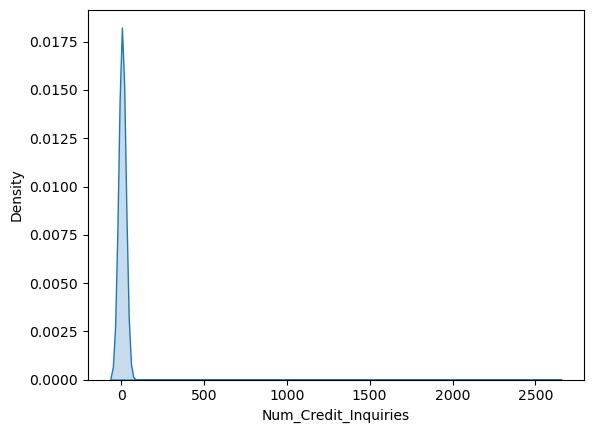

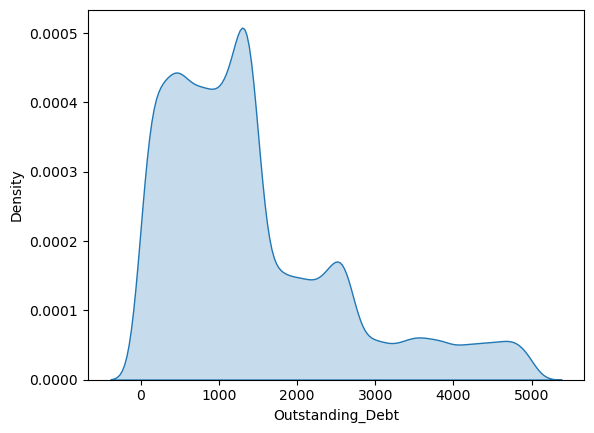

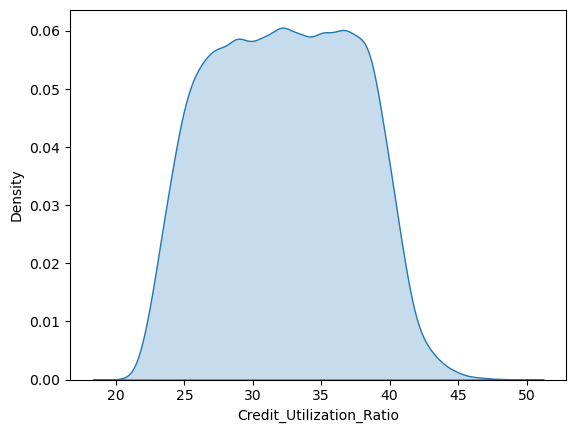

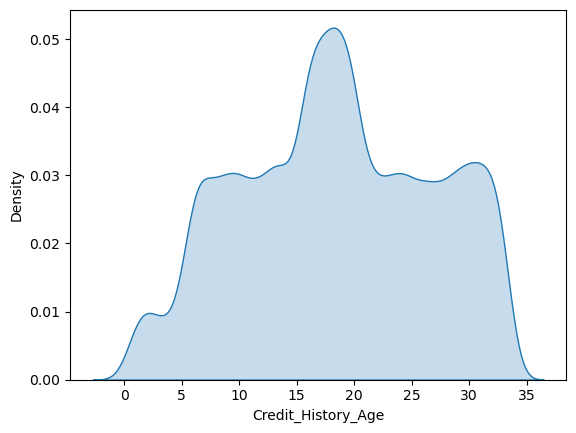

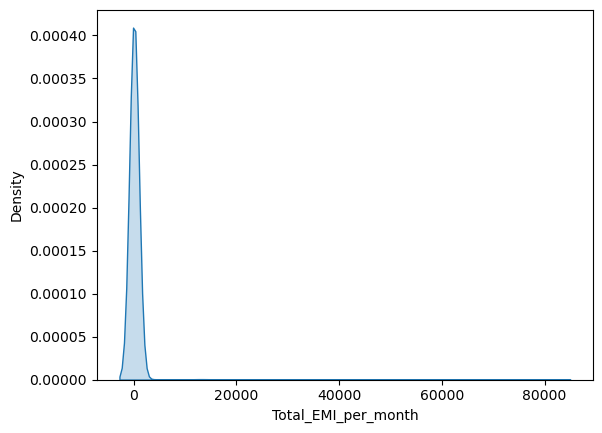

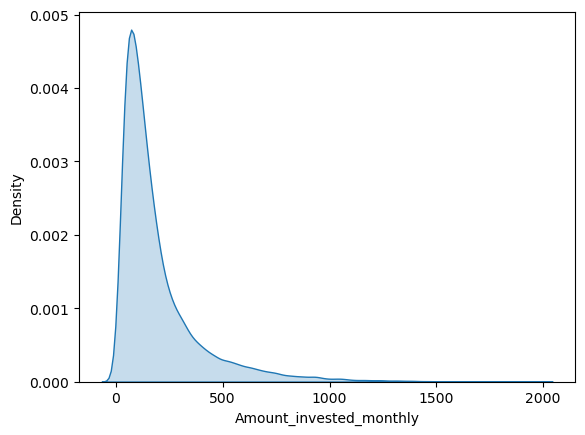

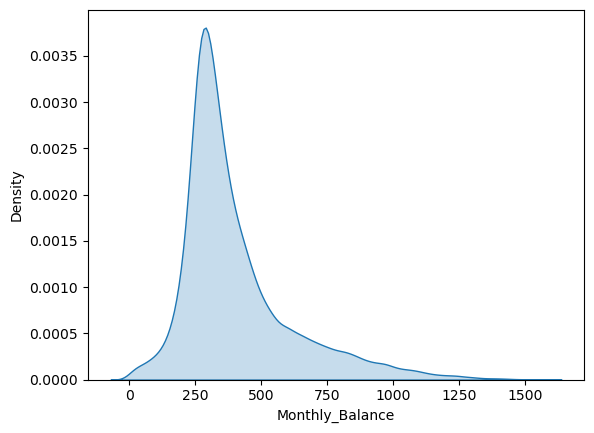

In [184]:
for col in X_train.drop(columns = cat_features).columns:
    sns.kdeplot(X_train[col], fill=True)
    plt.show()

По графикам видно, что некоторые признаки, такие как 'Monthly_Inhand_Salary', 'Delay_from_due_date', 'Amount_invested_monthly', 'Monthly_Balance', имеют распределение, приближенное к логнормальному, то есть горб скошен в левую часть и имеют тяжелый хвост справа. Обучим 2 модели: 1-я будет учиться на всех признаках без изменений, а 2-я - на том же датасете, но с прологарифмированными логнормальными признаками и сравним качество

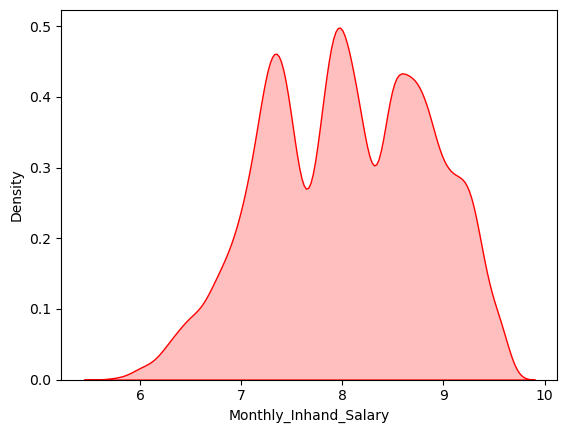

C:\Users\bvo5\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\bvo5\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\bvo5\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\bvo5\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


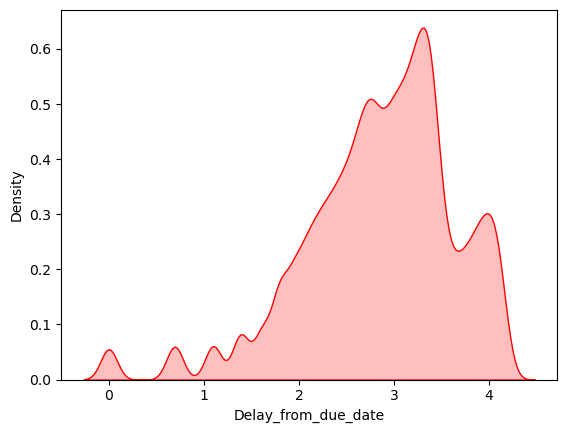

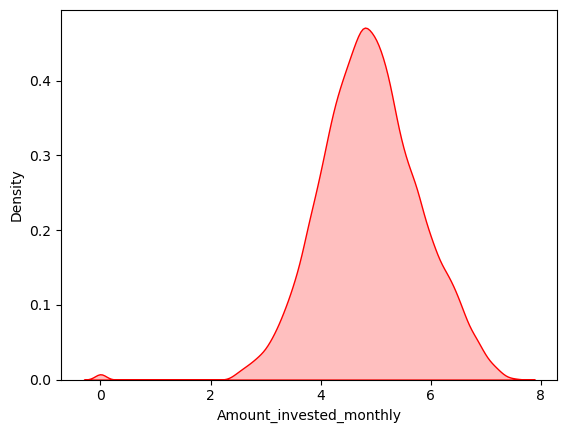

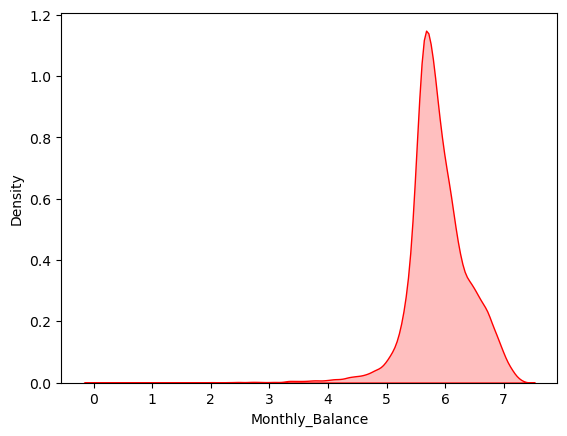

In [186]:
# Пробуем прологарифмировать некоторые признаки, чьи распределения скошены влевы и имеют тяжелый правый хвост, чтобы приблзить их к нормальному распределению
lognorm_features = ['Monthly_Inhand_Salary', 'Delay_from_due_date', 'Amount_invested_monthly', 'Monthly_Balance']
y_log, X_log = train['Credit_Score'], train.drop('Credit_Score', axis=1) 
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(X_log, y_log, test_size=0.2, random_state=42)
for col in lognorm_features:
    X_train_log[col] = np.log(X_train_log[col]+1)
    X_test_log[col] = np.log(X_test_log[col]+1)
    sns.kdeplot(X_train_log[col], fill=True, color='red')
    plt.show()

Распределение этих признаков более менее выравнялось, модели будет легче справляться с данными, распределенными нормально.

ОЦЕНКА КАЧЕСТВА

Так как решается задача кредитного скоринга, то будем ставить задачу максимизировать Recall на классе Poor, так как банк не в интересах выдать кредит ненадежному клиенту и в то же время не сильно жертвовать Precision на классе Good. Для каждой модели выведим матрицу ошибок на тестовой выборке, а так-же построим ROC-кривую и посчтаем AUC для тестовой выборки

In [190]:
# Предикты на трейне и тесте
def evaluate(model, X_train, y_train, X_test, y_test):
    classes = ['Good', 'Standard', 'Poor']
    y_pred_test = model.predict(X_test)
    y_proba_test = model.predict_proba(X_test)
    
    y_pred_train = model.predict(X_train)
    y_proba_train = model.predict_proba(X_train)
    
    # Метрики
    print("Accuracy (Train):", accuracy_score(y_train, y_pred_train))
    print("Отчет по классификации (Train):")
    print(classification_report(y_train, y_pred_train), "\n\n")
    
    print("Accuracy (Test):", accuracy_score(y_test, y_pred_test))
    print("Отчет по классификации (Test):")
    print(classification_report(y_test, y_pred_test))
    
    #Матрица ошибок на тесте
    cm = confusion_matrix(y_test, y_pred_test, labels=classes)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Good', 'Standard', 'Poor'], 
                yticklabels=['Good', 'Standard', 'Poor'])
    plt.ylabel('Реальные значения')
    plt.xlabel('Предсказания модели')
    plt.title('Матрица ошибок (Confusion Matrix)')
    plt.show()
    print("\n")
    #ROC-AUC
    
    y_test_bin = label_binarize(y_test, classes=classes)
    y_score = model.predict_proba(X_test)
    n_classes = 3
    
    plt.figure(figsize=(10, 7))
    
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'ROC curve {classes[i]} (area = {roc_auc:0.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2) 
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-class ROC Curve (CatBoost)')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

Обучение

Попробуем найти лучшие параметры через GridSearchCV

In [193]:
'''
model = CatBoostClassifier(logging_level='Silent', cat_features=cat_features, task_type='GPU')

# Сетка параметров
param_grid = {
    'depth': [4, 6, 8],
    'learning_rate': [0.03, 0.06, 0.1, 0.5, 1],
    'iterations': [100,150,200,500],
    # Пробуем разные веса, чтобы сильнее штрафовать за ошибки в Poor
    'class_weights': [[1, 1, 3], [1, 1, 4], [2, 1, 5], [2, 1, 5]] 
}

grid_search = GridSearchCV(estimator=model, 
                           param_grid=param_grid, 
                           scoring='recall_macro', 
                           cv=3)

grid_search.fit(X_train, y_train)

print(f"Лучшие параметры: {grid_search.best_params_}")
'''

'\nmodel = CatBoostClassifier(logging_level=\'Silent\', cat_features=cat_features, task_type=\'GPU\')\n\n# Сетка параметров\nparam_grid = {\n    \'depth\': [4, 6, 8],\n    \'learning_rate\': [0.03, 0.06, 0.1, 0.5, 1],\n    \'iterations\': [100,150,200,500],\n    # Пробуем разные веса, чтобы сильнее штрафовать за ошибки в Poor\n    \'class_weights\': [[1, 1, 3], [1, 1, 4], [2, 1, 5], [2, 1, 5]] \n}\n\ngrid_search = GridSearchCV(estimator=model, \n                           param_grid=param_grid, \n                           scoring=\'recall_macro\', \n                           cv=3)\n\ngrid_search.fit(X_train, y_train)\n\nprint(f"Лучшие параметры: {grid_search.best_params_}")\n'

In [194]:
model1 = CatBoostClassifier(
    iterations=500,
    learning_rate=0.5,
    depth=8,
    class_weights={'Good': 1, 'Standard': 1, 'Poor': 3},
    cat_features=cat_features,
    verbose=25,
    task_type='GPU'
)

model2 = CatBoostClassifier(
    iterations=500,
    learning_rate=0.5,
    depth=8,
    class_weights={'Good': 1, 'Standard': 1, 'Poor': 3},
    cat_features=cat_features,
    verbose=25,
    task_type='GPU'
)

Создаем два датасета для двух моделей - обычный и частично прологарифмированный

In [196]:
train_data1 = Pool(
    data=X_train, 
    label=y_train, 
    cat_features=cat_features,
)

train_data2 = Pool(
    data=X_train_log, 
    label=y_train_log, 
    cat_features=cat_features,
)
print("Обычное обучение")
model1.fit(train_data1)
print("\n\nОбучение с отлографмированными столбцами")
model2.fit(train_data2)

Обычное обучение
0:	learn: 0.7948545	total: 13.7ms	remaining: 6.85s
25:	learn: 0.5001438	total: 320ms	remaining: 5.83s
50:	learn: 0.4537464	total: 617ms	remaining: 5.43s
75:	learn: 0.4181705	total: 902ms	remaining: 5.03s
100:	learn: 0.3901153	total: 1.27s	remaining: 5.02s
125:	learn: 0.3651979	total: 1.57s	remaining: 4.65s
150:	learn: 0.3434831	total: 1.86s	remaining: 4.29s
175:	learn: 0.3242440	total: 2.16s	remaining: 3.98s
200:	learn: 0.3077712	total: 2.48s	remaining: 3.68s
225:	learn: 0.2924501	total: 2.77s	remaining: 3.36s
250:	learn: 0.2760115	total: 3.1s	remaining: 3.07s
275:	learn: 0.2626013	total: 3.4s	remaining: 2.76s
300:	learn: 0.2487063	total: 3.73s	remaining: 2.46s
325:	learn: 0.2376643	total: 4.01s	remaining: 2.14s
350:	learn: 0.2252316	total: 4.3s	remaining: 1.83s
375:	learn: 0.2140052	total: 4.61s	remaining: 1.52s
400:	learn: 0.2038304	total: 4.9s	remaining: 1.21s
425:	learn: 0.1935700	total: 5.2s	remaining: 903ms
450:	learn: 0.1829936	total: 5.49s	remaining: 597ms
475:

Качество первой модели:

Accuracy (Train): 0.9229920274098966
Отчет по классификации (Train):
              precision    recall  f1-score   support

        Good       0.93      0.91      0.92     10802
        Poor       0.86      0.99      0.92     17534
    Standard       0.97      0.89      0.93     32372

    accuracy                           0.92     60708
   macro avg       0.92      0.93      0.92     60708
weighted avg       0.93      0.92      0.92     60708
 


Accuracy (Test): 0.7721552348949068
Отчет по классификации (Test):
              precision    recall  f1-score   support

        Good       0.70      0.65      0.67      2656
        Poor       0.74      0.86      0.80      4417
    Standard       0.82      0.76      0.79      8104

    accuracy                           0.77     15177
   macro avg       0.75      0.76      0.75     15177
weighted avg       0.77      0.77      0.77     15177



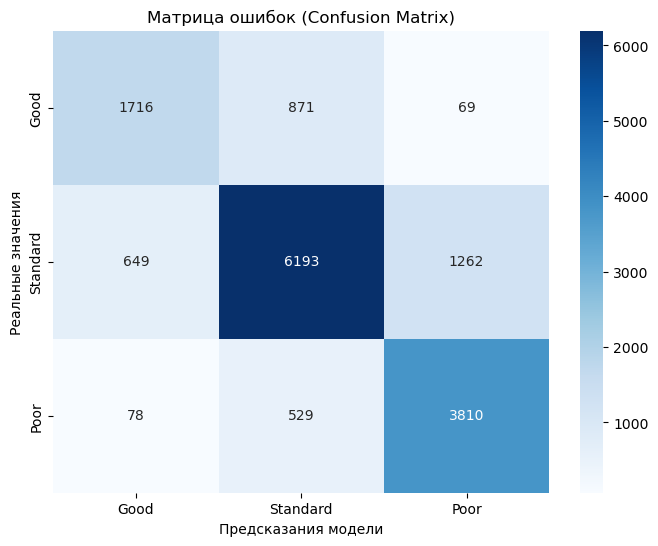

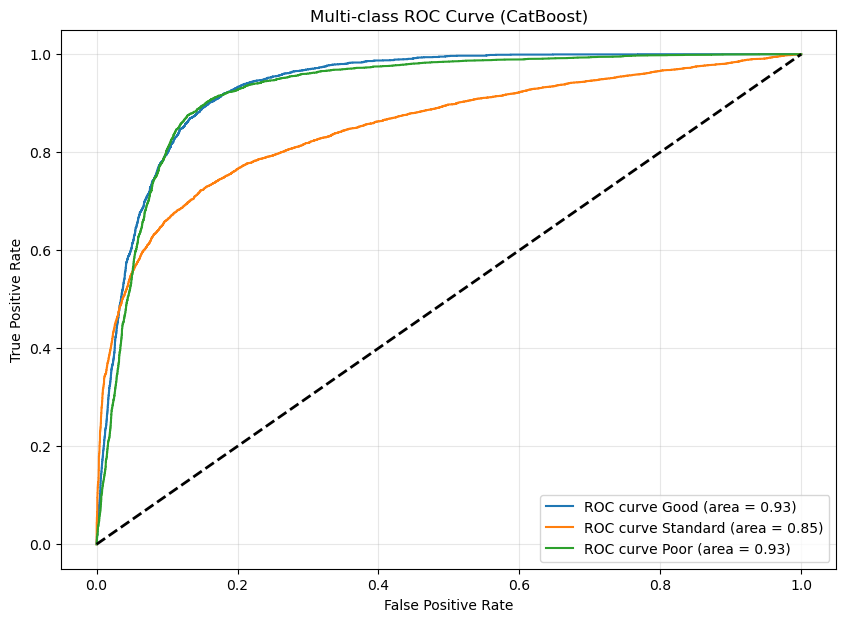

In [198]:
evaluate(model1, X_train, y_train, X_test, y_test)

Качество второй модели (с логарифмом):

Accuracy (Train): 0.9238980035580154
Отчет по классификации (Train):
              precision    recall  f1-score   support

        Good       0.93      0.91      0.92     10802
        Poor       0.86      0.99      0.92     17534
    Standard       0.97      0.89      0.93     32372

    accuracy                           0.92     60708
   macro avg       0.92      0.93      0.92     60708
weighted avg       0.93      0.92      0.92     60708
 


Accuracy (Test): 0.7700467813138301
Отчет по классификации (Test):
              precision    recall  f1-score   support

        Good       0.70      0.64      0.67      2656
        Poor       0.74      0.87      0.80      4417
    Standard       0.81      0.76      0.79      8104

    accuracy                           0.77     15177
   macro avg       0.75      0.76      0.75     15177
weighted avg       0.77      0.77      0.77     15177



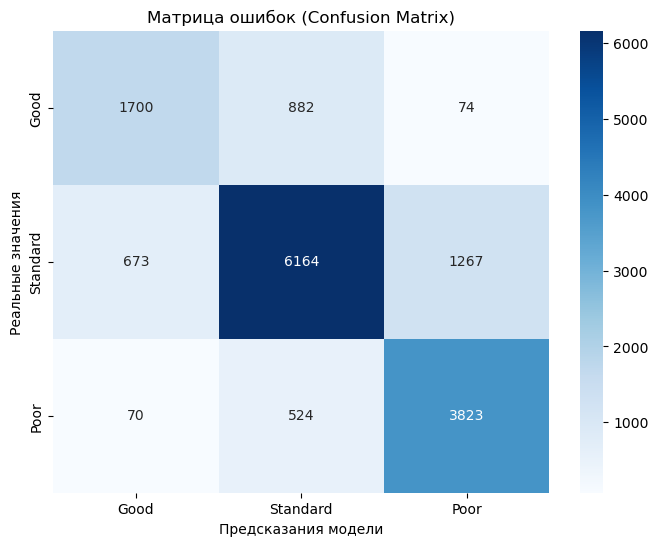

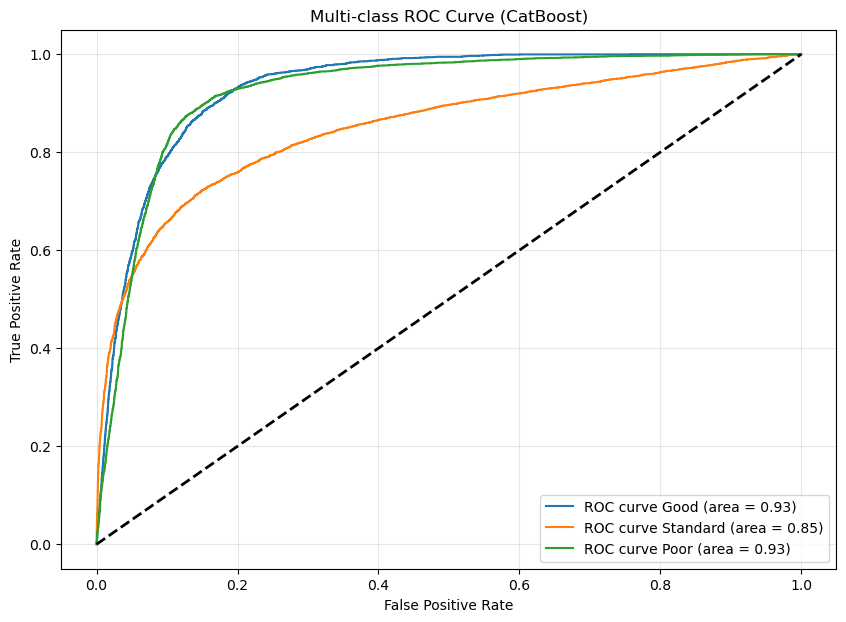

In [200]:
evaluate(model2, X_train_log, y_train_log, X_test_log, y_test_log)

Можно сделать вывод, что вторая модель дает результаты чуть лучше чем первая, если оценивать способность предсказывать Good и Poor, делая упор на Poor. Метрики AUC у первой и второй модели почти одинаковые.

Использование модели для новых входных данных
Для новых входных данных нужно произвести те же преобразования, что и с тренировочным датасетом, включая логарифмирование некоторых столбцов. Для преобразований достаточно будет передать исходный датасет в формате pd.DataFrame в последнюю функцию transform_data(), которая вызоывет остальные 2

In [203]:
# Для далнейшего использования модели вынесим преобразование исходной таблицы в отдельные функции

def Credit_History_Age(s=str):
    try:
        y, m = map(int, s[:s.rfind(' ')].split(" Years and "))
        return y + m/12
    except:
        return s
        
def drop_artifact_rows(df, columns):
    mask = pd.Series(False, index=df.index)
    for col in columns:
        converted = pd.to_numeric(df[col], errors='coerce')
        artifacts = df[col].notna() & converted.isna()
        mask = mask | artifacts
        #print(f"В колонке '{col}' найдено артефактов: {artifacts.sum()}")

    df_cleaned = df[~mask].copy()
    for col in columns:
        df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='ignore')
    return df_cleaned
    
def transform_data(df):
    df = df.drop(columns=['ID', 'Customer_ID', 'Name', 'SSN'])
    df["Credit_History_Age"] = df["Credit_History_Age"].apply(lambda s: Credit_History_Age(s))
    df = drop_artifact_rows(df, ["Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Outstanding_Debt", "Amount_invested_monthly", "Monthly_Balance"])
    cat_features = ["Month", "Occupation", "Type_of_Loan", "Credit_Mix", "Payment_Behaviour", "Payment_of_Min_Amount"]
    for col in cat_features:
        df[col] = df[col].astype(str)
    try:
        df = df.drop('Credit_Score', axis=1)
    except:
        pass
        
    lognorm_features = ['Monthly_Inhand_Salary', 'Delay_from_due_date', 'Amount_invested_monthly', 'Monthly_Balance']
    for col in lognorm_features:
        df[col] = np.log(X_train_log[col]+1)
        df[col] = np.log(X_test_log[col]+1)
        
    return df
    

In [204]:
transform_data(train_copy).head(5)

C:\Users\bvo5\AppData\Local\Temp\ipykernel_14276\4284637006.py:20: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='ignore')
C:\Users\bvo5\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,January,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,_,809.98,26.822620,22.083333,No,49.574949,NaN,High_spent_Small_value_payments,NaN
1,February,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,31.944960,NaN,No,49.574949,NaN,Low_spent_Large_value_payments,NaN
3,April,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,31.377862,22.333333,No,49.574949,NaN,Low_spent_Small_value_payments,NaN
4,May,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,24.797347,22.416667,No,49.574949,NaN,High_spent_Medium_value_payments,NaN
5,June,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,27.262259,22.500000,No,49.574949,1.638985,!@9#%8,1.921806
